# camera_r / camera_fl：Lap2 SfM 建图 + Lap3 定位实验

**Kernel:** `pixel-racers`

对应 `SFM_FEASIBILITY.md`：
1. **§1–8 `camera_r`**：Lap2 建图 → Lap3 NetVLAD/LightGlue/PnP → 误差与失败区
2. **§9 `camera_fl`**：同一套思路独立建 `Map_fl` + Lap3 query（**不融合**）
3. **§10**：对齐比较两路，看并集成功率能否补失败

默认**全圈**。`RUN_FL=True` 时跑前视；首次 NetVLAD 会下载权重。

已有 `map_bundle.npz` 时跳过建图；设 `OVERRIDE_MAP=True` 强制重建。


In [16]:
from __future__ import annotations

import importlib
import json
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import cv2
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
if ROOT.name == "3d-map-test":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "3d-map-test"))

import sfm_experiment as sfm

sfm = importlib.reload(sfm)

OUT = ROOT / "3d-map-test" / "outputs"
OUT.mkdir(parents=True, exist_ok=True)

# ---- 实验规模（全圈：MAX=None；烟测可改小 MAX / 加大 STRIDE）----
MAP_LAP = 2
QUERY_LAP = 3
MAP_MAX_FRAMES = None   # None = 全圈
QUERY_MAX_FRAMES = None
MAP_STRIDE = 1          # 建图抽帧
QUERY_STRIDE = 1
SP_RESIZE = 512
SP_MAX_KP = 1024
MIN_NN_DIST = 0.50      # 歧义过滤：同图描述子 L2 近邻下限（过大如0.85会杀太多点）
MATCH_WINDOW = 2
TOP_K = 5
EPI_THRESH_PX = 6.0    # GT+外参残差下 3px 往往过严
USE_NETVLAD = True      # False 时跳过检索定位段
RUN_FL = True           # §9–10：Lap2/3 camera_fl 独立建图+定位（不融合）
OVERRIDE_MAP = False    # True=强制重建图；False=若存在 map_bundle.npz 则加载跳过

print("ROOT", ROOT)
print("MCAP", sfm.DEFAULT_MCAP, "exists", sfm.DEFAULT_MCAP.is_file())
print("device will prefer", sfm.pick_device())
print("OVERRIDE_MAP", OVERRIDE_MAP)


ROOT /Users/hbai/SchubKI/PixelRacers
MCAP /Users/hbai/SchubKI/c0_2026-10-13_22-53-42_camloc/c0_2026-10-13_22-53-42_camloc_0.mcap exists True
device will prefer mps
OVERRIDE_MAP False


## 1. 标定 / GT / 圈次

In [17]:
calib = sfm.load_camera_calib("r")
gt = sfm.load_gt()
lap_map = sfm.load_lap(MAP_LAP)
lap_q = sfm.load_lap(QUERY_LAP)

print("K_r\n", calib.K)
print("T_base_r t", calib.T_base_cam[:3, 3])
print("map lap", MAP_LAP, lap_map["duration_s"], "s")
print("query lap", QUERY_LAP, lap_q["duration_s"], "s")
if RUN_FL:
    calib_fl = sfm.load_camera_calib("fl")
    print("K_fl\n", calib_fl.K)
    print("T_base_fl t", calib_fl.T_base_cam[:3, 3])


K_r
 [[1.49113827e+03 0.00000000e+00 7.53630340e+02]
 [0.00000000e+00 1.49177455e+03 4.86049730e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
T_base_r t [-2.28 -0.    0.07]
map lap 2 167.594185587 s
query lap 3 123.628026554 s
K_fl
 [[2.60119850e+03 0.00000000e+00 7.75091110e+02]
 [0.00000000e+00 2.58987007e+03 5.21335600e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
T_base_fl t [0.94151915 0.19650187 0.33862352]


## 2. 加载 Lap2 `camera_r` 全圈（去畸变 + GT 位姿）

若 `outputs/map/map_bundle.npz` 已存在且 `OVERRIDE_MAP=False`，跳过抽帧/特征/三角化，直接加载。


load camera_r:   0%|          | 0/1675 [00:00<?, ?frm/s]

map frames=1675  (26.7s)
first stamp 1791918444880774173 gt (6.8746, 3.2415, -0.222, 0.119339)


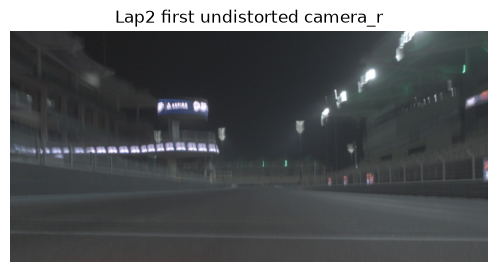

In [18]:
OVERRIDE_MAP = globals().get("OVERRIDE_MAP", False)
map_dir = OUT / "map"
map_dir.mkdir(parents=True, exist_ok=True)
SKIP_MAP_R = sfm.map_ready(map_dir) and not OVERRIDE_MAP

if SKIP_MAP_R:
    print(f"SKIP rebuild camera_r map — load {map_dir / sfm.MAP_BUNDLE_NAME} (set OVERRIDE_MAP=True to rebuild)")
    map_frames, points = sfm.load_map_bundle(map_dir)
    observations = []
    print(f"loaded map_frames={len(map_frames)} points={len(points)}")
else:
    if sfm.map_ready(map_dir) and OVERRIDE_MAP:
        print("OVERRIDE_MAP=True — rebuilding camera_r map")
    t0 = time.perf_counter()
    map_frames = sfm.extract_frames_from_mcap(
        sfm.DEFAULT_MCAP,
        int(lap_map["start_ns"]),
        int(lap_map["end_ns"]),
        calib,
        gt,
        camera="r",
        max_frames=MAP_MAX_FRAMES,
        stride=MAP_STRIDE,
    )
    print(f"map frames={len(map_frames)}  ({time.perf_counter()-t0:.1f}s)")
    if map_frames:
        print("first stamp", map_frames[0].stamp_ns, "gt", map_frames[0].gt_xyzyaw)
        plt.figure(figsize=(10, 3))
        plt.imshow(cv2.cvtColor(map_frames[0].bgr_undist, cv2.COLOR_BGR2RGB))
        plt.title("Lap2 first undistorted camera_r")
        plt.axis("off")
        plt.show()


## 3. SuperPoint + 歧义过滤 + NetVLAD（地图帧）

local device mps resize 512
loading NetVLAD (may download Pitts30K .mat on first run)...


SuperPoint(+NetVLAD):   0%|          | 0/1675 [00:00<?, ?frm/s]

feature extract done in 439.5s
kpts per frame: med 146.0 min 44 max 367


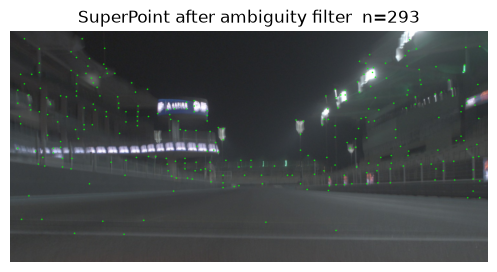

In [19]:
local = sfm.LocalFeatures(max_keypoints=SP_MAX_KP, resize=SP_RESIZE)
print("local device", local.device, "resize", local.resize)

netvlad = None
if USE_NETVLAD:
    print("loading NetVLAD (may download Pitts30K .mat on first run)...")
    netvlad = sfm.NetVLADGlobal(device=local.device)

if SKIP_MAP_R:
    print("SKIP feature extract on map frames (loaded from bundle)")
    nk = [len(f.kpts) for f in map_frames]
    print("kpts per frame: med", np.median(nk), "min", np.min(nk), "max", np.max(nk))
else:
    t0 = time.perf_counter()
    sfm.run_local_and_global(map_frames, local, netvlad, min_nn_dist=MIN_NN_DIST)
    print(f"feature extract done in {time.perf_counter()-t0:.1f}s")
    nk = [len(f.kpts) for f in map_frames]
    print("kpts per frame: med", np.median(nk), "min", np.min(nk), "max", np.max(nk))

    fr0 = map_frames[0]
    if fr0.bgr_undist.size > 3:
        vis = fr0.bgr_undist.copy()
        for x, y in fr0.kpts.astype(int):
            cv2.circle(vis, (x, y), 2, (0, 255, 0), -1, cv2.LINE_AA)
        plt.figure(figsize=(10, 3))
        plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        plt.title(f"SuperPoint after ambiguity filter  n={len(fr0.kpts)}")
        plt.axis("off")
        plt.show()


## 4. ±2 LightGlue + GT 极线三角化 → 稀疏地图

SfM triangulate:   0%|          | 0/1675 [00:00<?, ?frm/s]

points=45073  obs=45073  (263.0s)
wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/map/points3D.ply


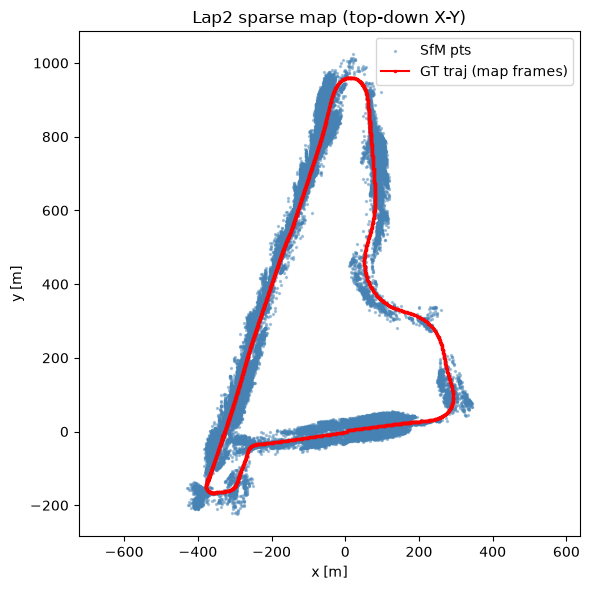

In [20]:
if SKIP_MAP_R:
    print(f"SKIP build_map — using loaded points ({len(points)})")
    ply_path = map_dir / "points3D.ply"
    print("existing", ply_path, "exists", ply_path.is_file())
else:
    t0 = time.perf_counter()
    points, observations = sfm.build_map(
        map_frames,
        local,
        calib.K,
        window=MATCH_WINDOW,
        min_baseline_m=0.8,
        epi_thresh_px=EPI_THRESH_PX,
    )
    print(f"points={len(points)}  obs={len(observations)}  ({time.perf_counter()-t0:.1f}s)")
    ply_path = map_dir / "points3D.ply"
    sfm.save_ply(ply_path, points)
    print("wrote", ply_path)

if len(points):
    xy = np.array([f.gt_xyzyaw[:2] for f in map_frames])
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(points[:, 0], points[:, 1], s=2, c="steelblue", alpha=0.4, label="SfM pts")
    ax.plot(xy[:, 0], xy[:, 1], "r.-", ms=3, label="GT traj (map frames)")
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend()
    ax.set_title("Lap2 sparse map (top-down X-Y)" + (" [loaded]" if SKIP_MAP_R else ""))
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    fig.tight_layout()
    fig.savefig(map_dir / "map_xy.png", dpi=120)
    plt.show()


## 5. 保存 NetVLAD 地图库

In [21]:
map_dir.mkdir(parents=True, exist_ok=True)

if SKIP_MAP_R:
    print("SKIP NetVLAD/map_bundle save — already on disk:", map_dir / sfm.MAP_BUNDLE_NAME)
    if (map_dir / "netvlad_db.npz").is_file():
        G = np.load(map_dir / "netvlad_db.npz")["descriptors"]
        print("NetVLAD db", G.shape)
else:
    # 写入可重载 bundle（含特征），供下次跳过建图
    bundle = sfm.save_map_bundle(map_dir, map_frames, points)
    print("wrote map bundle", bundle)
    if USE_NETVLAD and map_frames[0].global_desc is not None:
        G = np.stack([f.global_desc for f in map_frames], 0)
        print("NetVLAD db", G.shape, "->", map_dir / "netvlad_db.npz")
        sims = (G[:-1] * G[1:]).sum(1)
        print("adjacent cosine: med", float(np.median(sims)), "min", float(sims.min()))
    else:
        print("skip NetVLAD in bundle (no global_desc)")


wrote map bundle /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/map/map_bundle.npz
NetVLAD db (1675, 4096) -> /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/map/netvlad_db.npz
adjacent cosine: med 0.6661254167556763 min 0.4320785105228424


## 6. Lap3 查询：特征 + NetVLAD top-5 + LightGlue + PnP

In [22]:
if not USE_NETVLAD:
    raise RuntimeError("定位段需要 USE_NETVLAD=True")
if len(points) < 30:
    print("WARNING: few map points; localization may fail")

t0 = time.perf_counter()
query_frames = sfm.extract_frames_from_mcap(
    sfm.DEFAULT_MCAP,
    int(lap_q["start_ns"]),
    int(lap_q["end_ns"]),
    calib,
    gt,
    camera="r",
    max_frames=QUERY_MAX_FRAMES,
    stride=QUERY_STRIDE,
)
print(f"query frames={len(query_frames)}  load {time.perf_counter()-t0:.1f}s")

t0 = time.perf_counter()
sfm.run_local_and_global(query_frames, local, netvlad, min_nn_dist=MIN_NN_DIST)
print(f"query features {time.perf_counter()-t0:.1f}s")

from tqdm.auto import tqdm

results = []
t0 = time.perf_counter()
for i, q in enumerate(tqdm(query_frames, desc="localize Lap3", unit="qry")):
    r = sfm.localize_query(
        q,
        map_frames,
        points,
        local,
        calib.K,
        calib.T_base_cam,
        top_k=TOP_K,
    )
    results.append(r)
    tqdm.write(
        f"[{i}] ok={r['ok']} top5={r['topk']} n_corr={r['n_pnp_corr']} "
        f"inl={r['n_pnp_inl']} err_xy={r['err_xy']} yaw={r['err_yaw_deg']}"
    )
print(f"localize {time.perf_counter()-t0:.1f}s")


load camera_r:   0%|          | 0/1236 [00:00<?, ?frm/s]

query frames=1235  load 21.8s


SuperPoint(+NetVLAD):   0%|          | 0/1235 [00:00<?, ?frm/s]

query features 272.8s


localize Lap3:   0%|          | 0/1235 [00:00<?, ?qry/s]

[0] ok=True top5=[1672, 1674, 1669, 0, 1671] n_corr=321 inl=30 err_xy=0.4659105576569088 yaw=-0.008181755776031672
[1] ok=True top5=[1672, 1671, 1673, 1670, 1669] n_corr=319 inl=34 err_xy=0.3873966710010085 yaw=-0.11889398008310799
[2] ok=True top5=[1671, 1672, 1673, 1674, 1670] n_corr=284 inl=29 err_xy=0.5463489368756086 yaw=0.26252120635853826
[3] ok=True top5=[1671, 1672, 1674, 4, 1667] n_corr=293 inl=25 err_xy=2.27402699068466 yaw=-0.1605490630217476
[4] ok=True top5=[1672, 1674, 4, 1671, 1673] n_corr=276 inl=22 err_xy=2.346348928336868 yaw=-0.015820909907062176
[5] ok=True top5=[1672, 1673, 10, 1674, 9] n_corr=231 inl=20 err_xy=7.501046466468302 yaw=0.6526517638734202
[6] ok=True top5=[4, 9, 1673, 11, 6] n_corr=220 inl=20 err_xy=1.6624615917768975 yaw=-0.8286254243732002
[7] ok=True top5=[4, 9, 11, 6, 10] n_corr=204 inl=19 err_xy=2.230774842982305 yaw=0.2768959247688634
[8] ok=True top5=[1670, 12, 10, 4, 1672] n_corr=254 inl=17 err_xy=1.183963326034897 yaw=-0.013429769718426344
[9

## 7. 误差随时间 + 轨迹对比（同 odometry 风格）

wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/errors.csv
success 709/1235
{'xy_mean_m': 3.3454822557594874, 'xy_median_m': 1.186318606457956, 'xy_p95_m': 11.291311898682864, 'yaw_median_deg': 0.2224933720305464}
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/lap03_err_vs_time.png


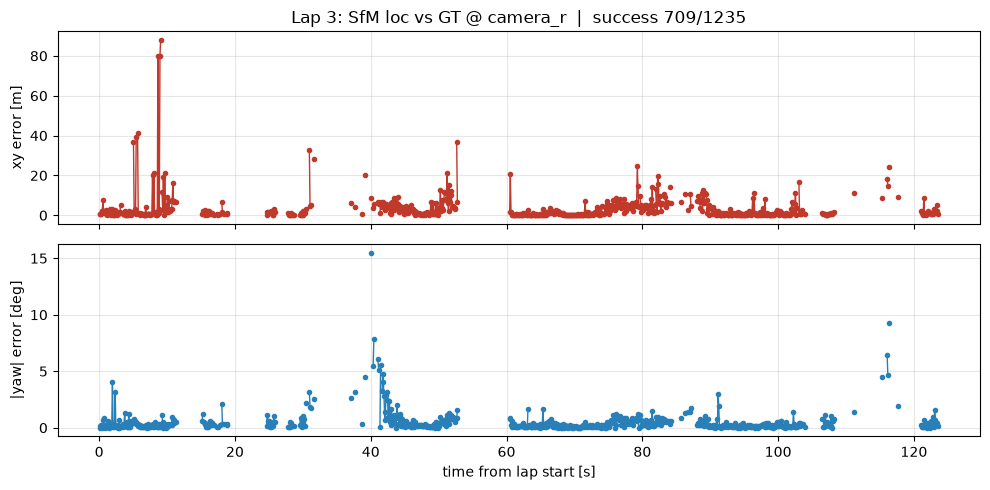

saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/lap03_traj_vs_gt.png


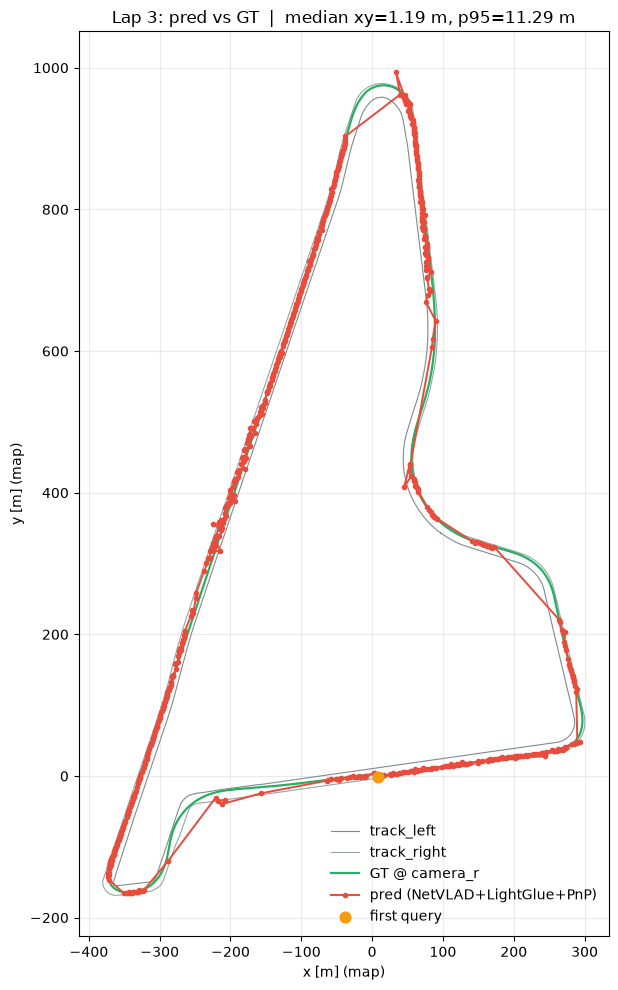

In [23]:
import pandas as pd

loc_dir = OUT / "loc_lap3"
loc_dir.mkdir(parents=True, exist_ok=True)

stamps = np.array([q.stamp_ns for q in query_frames], dtype=np.int64)
t0_ns = int(lap_q["start_ns"])
t_rel = (stamps - t0_ns) * 1e-9

gt_xy = np.array([q.gt_xyzyaw[:2] for q in query_frames], dtype=np.float64)
gt_yaw = np.array([q.gt_xyzyaw[3] for q in query_frames], dtype=np.float64)
pred_xy = np.full((len(results), 2), np.nan)
pred_yaw = np.full(len(results), np.nan)
err_xy = np.full(len(results), np.nan)
err_yaw_deg = np.full(len(results), np.nan)
ok_mask = np.array([bool(r["ok"]) for r in results])

for i, r in enumerate(results):
    if not r["ok"]:
        continue
    pred_xy[i] = r["pred"][:2]
    pred_yaw[i] = r["pred"][3]
    err_xy[i] = r["err_xy"]
    err_yaw_deg[i] = abs(r["err_yaw_deg"])

rows = []
for i, (q, r) in enumerate(zip(query_frames, results)):
    rows.append(
        {
            "idx": i,
            "stamp_ns": int(q.stamp_ns),
            "t_rel_s": float(t_rel[i]),
            "ok": bool(r["ok"]),
            "gt_x": float(q.gt_xyzyaw[0]),
            "gt_y": float(q.gt_xyzyaw[1]),
            "gt_yaw": float(q.gt_xyzyaw[3]),
            "pred_x": None if not r["ok"] else float(r["pred"][0]),
            "pred_y": None if not r["ok"] else float(r["pred"][1]),
            "pred_yaw": None if not r["ok"] else float(r["pred"][3]),
            "err_xy": r["err_xy"],
            "err_yaw_deg": None if r["err_yaw_deg"] is None else abs(r["err_yaw_deg"]),
            "n_pnp_corr": r["n_pnp_corr"],
            "n_pnp_inl": r["n_pnp_inl"],
            "topk": json.dumps(r["topk"]),
        }
    )
df = pd.DataFrame(rows)
df.to_csv(loc_dir / "errors.csv", index=False)
print("wrote", loc_dir / "errors.csv")
print(f"success {ok_mask.sum()}/{len(results)}")

if ok_mask.any():
    summary = {
        "xy_mean_m": float(np.nanmean(err_xy)),
        "xy_median_m": float(np.nanmedian(err_xy)),
        "xy_p95_m": float(np.nanpercentile(err_xy, 95)),
        "yaw_median_deg": float(np.nanmedian(err_yaw_deg)),
    }
    print(summary)
else:
    summary = {"xy_median_m": float("nan"), "xy_p95_m": float("nan")}
    print("no successful localizations")

# --- 误差随时间（对齐 lap2_velocity_odometry）---
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(t_rel, err_xy, color="#c0392b", lw=1.0, marker="o", ms=3)
axes[0].set_ylabel("xy error [m]")
axes[0].grid(True, alpha=0.3)
axes[0].set_title(
    f"Lap {QUERY_LAP}: SfM loc vs GT @ camera_r  |  success {ok_mask.sum()}/{len(results)}"
)
axes[1].plot(t_rel, err_yaw_deg, color="#2980b9", lw=1.0, marker="o", ms=3)
axes[1].set_ylabel("|yaw| error [deg]")
axes[1].set_xlabel("time from lap start [s]")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
err_path = loc_dir / f"lap{QUERY_LAP:02d}_err_vs_time.png"
fig.savefig(err_path, dpi=150)
print("saved", err_path)
plt.show()

# --- 轨迹对比 + track_bounds ---
with open(sfm.EXTRACTED / "track_bounds.json") as f:
    track_bounds = json.load(f)


def polyline_xy(key: str) -> np.ndarray:
    pts = track_bounds[key]["points"]
    return np.array([[p["x"], p["y"]] for p in pts], dtype=np.float64)


track_left = polyline_xy("track_left")
track_right = polyline_xy("track_right")

fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(track_left[:, 0], track_left[:, 1], color="#7f8c8d", lw=0.8, label="track_left")
ax.plot(track_right[:, 0], track_right[:, 1], color="#95a5a6", lw=0.8, label="track_right")
ax.plot(gt_xy[:, 0], gt_xy[:, 1], color="#27ae60", lw=1.6, label="GT @ camera_r")
if ok_mask.any():
    ax.plot(
        pred_xy[ok_mask, 0],
        pred_xy[ok_mask, 1],
        color="#e74c3c",
        lw=1.4,
        marker="o",
        ms=3,
        label="pred (NetVLAD+LightGlue+PnP)",
    )
ax.scatter([gt_xy[0, 0]], [gt_xy[0, 1]], c="#f39c12", s=60, zorder=5, label="first query")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [m] (map)")
ax.set_ylabel("y [m] (map)")
ax.set_title(
    f"Lap {QUERY_LAP}: pred vs GT  |  median xy={summary['xy_median_m']:.2f} m, "
    f"p95={summary['xy_p95_m']:.2f} m"
)
ax.legend(loc="best", frameon=False)
ax.grid(True, alpha=0.25)
fig.tight_layout()
traj_path = loc_dir / f"lap{QUERY_LAP:02d}_traj_vs_gt.png"
fig.savefig(traj_path, dpi=150)
print("saved", traj_path)
plt.show()

## 8. 失败集中区域：每区抽取 5 张 query 图

对 `ok=False` 的连续失败段做聚类（中间穿插 ≤2 帧成功也合并），长度 ≥3 的视为集中失败区；每区沿时间均匀取 5 帧展示。

hard fails (ok=False): 526/1235
concentrated fail regions (len>=3): 12
  region[0] idx=[1081,1212) n=131  t=[108.3,121.3]s  xy≈(-320.5,-159.1)→(-60.3,-5.1)
  region[1] idx=[312,416) n=104  t=[31.3,41.6]s  xy≈(55.5,448.0)→(82.8,715.6)
  region[2] idx=[167,246) n=79  t=[16.8,24.6]s  xy≈(277.6,162.1)→(175.1,322.6)
  region[3] idx=[524,603) n=79  t=[52.6,60.4]s  xy≈(47.3,958.2)→(-35.5,905.8)
  region[4] idx=[834,881) n=47  t=[83.6,88.2]s  xy≈(-225.9,305.5)→(-262.2,195.7)
  region[5] idx=[111,154) n=43  t=[11.2,15.4]s  xy≈(282.0,44.4)→(287.5,124.3)
  region[6] idx=[1034,1065) n=31  t=[103.6,106.6]s  xy≈(-372.3,-140.4)→(-348.7,-164.3)
  region[7] idx=[259,278) n=19  t=[26.0,27.8]s  xy≈(137.4,333.9)→(94.4,360.1)
  region[8] idx=[285,295) n=10  t=[28.6,29.5]s  xy≈(79.2,376.8)→(66.3,398.6)
  region[9] idx=[303,309) n=6  t=[30.4,30.9]s  xy≈(58.3,422.7)→(56.1,436.6)
  region[10] idx=[55,59) n=4  t=[5.6,5.9]s  xy≈(161.0,21.7)→(169.2,22.8)
  region[11] idx=[1218,1222) n=4  t=[122.0,122.3]s  xy≈(-40

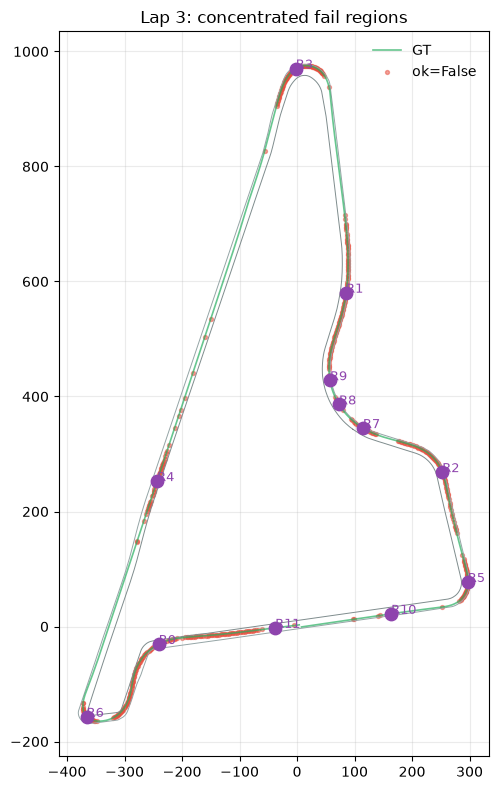


=== region[0] n_fail=131 sample=[1081, 1114, 1146, 1178, 1211] ===
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/region_00_idx1081-1211


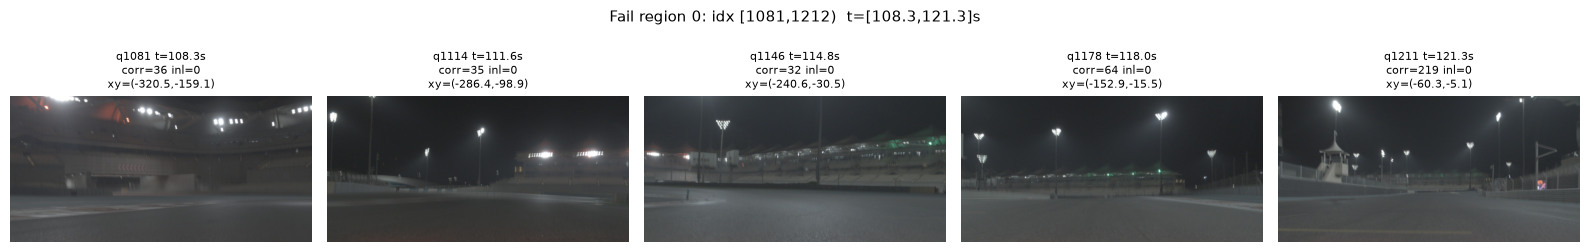


=== region[1] n_fail=104 sample=[312, 338, 364, 389, 415] ===
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/region_01_idx312-415


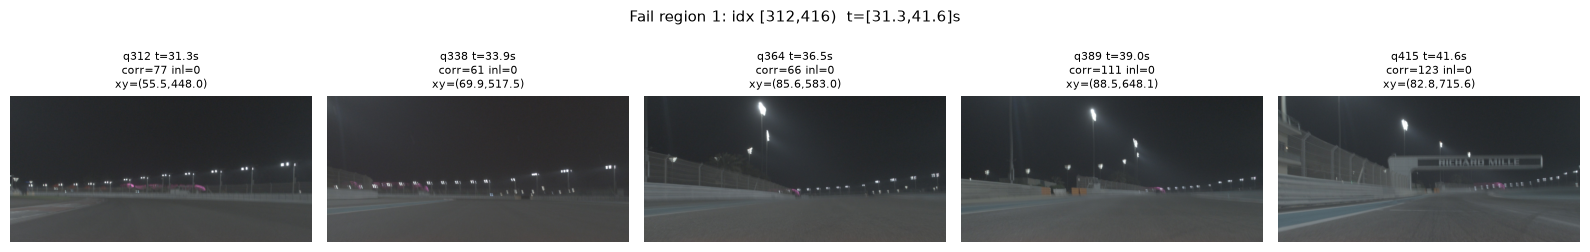


=== region[2] n_fail=79 sample=[167, 186, 206, 226, 245] ===
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/region_02_idx167-245


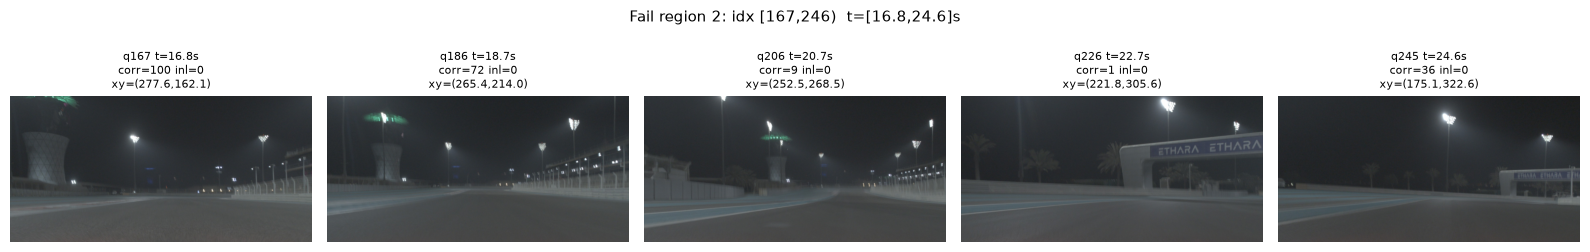


=== region[3] n_fail=79 sample=[524, 544, 563, 582, 602] ===
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/region_03_idx524-602


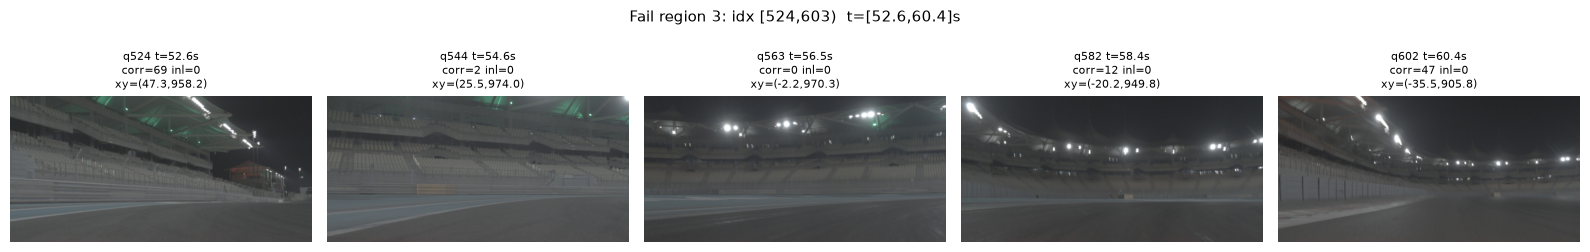


=== region[4] n_fail=47 sample=[834, 846, 857, 868, 880] ===
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/region_04_idx834-880


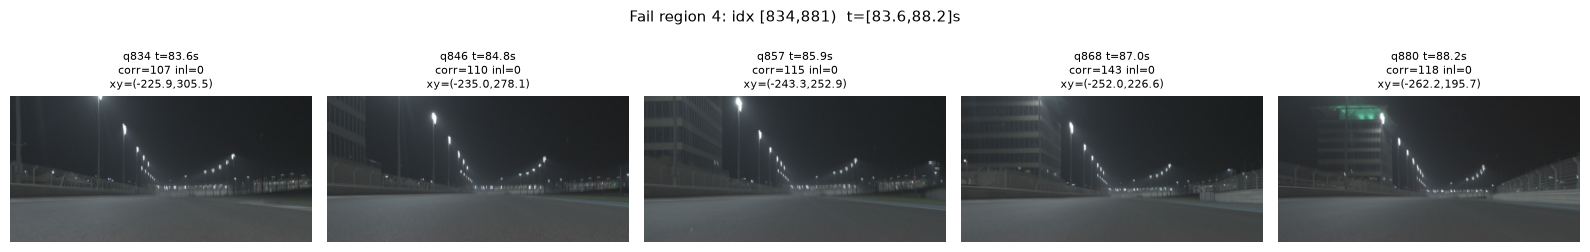


=== region[5] n_fail=43 sample=[111, 122, 132, 142, 153] ===
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/region_05_idx111-153


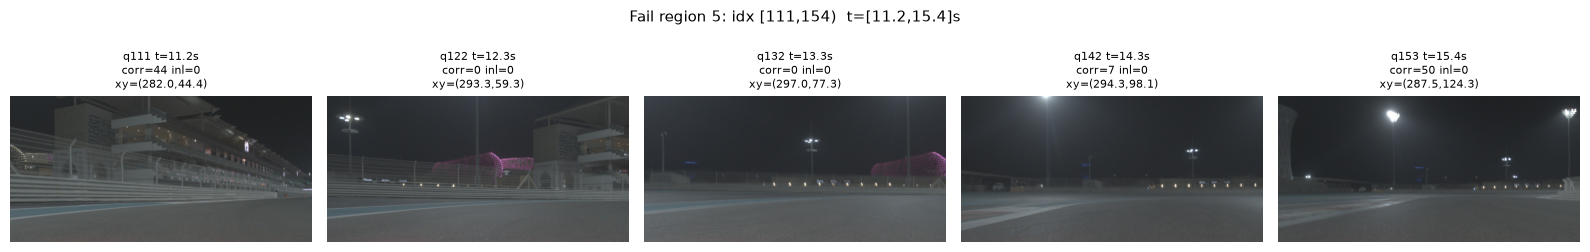


=== region[6] n_fail=31 sample=[1034, 1042, 1049, 1056, 1064] ===
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/region_06_idx1034-1064


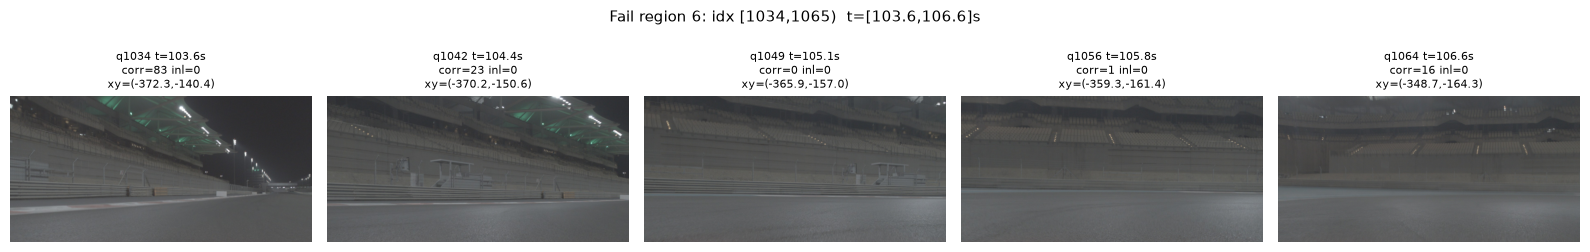


=== region[7] n_fail=19 sample=[259, 264, 268, 272, 277] ===
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/region_07_idx259-277


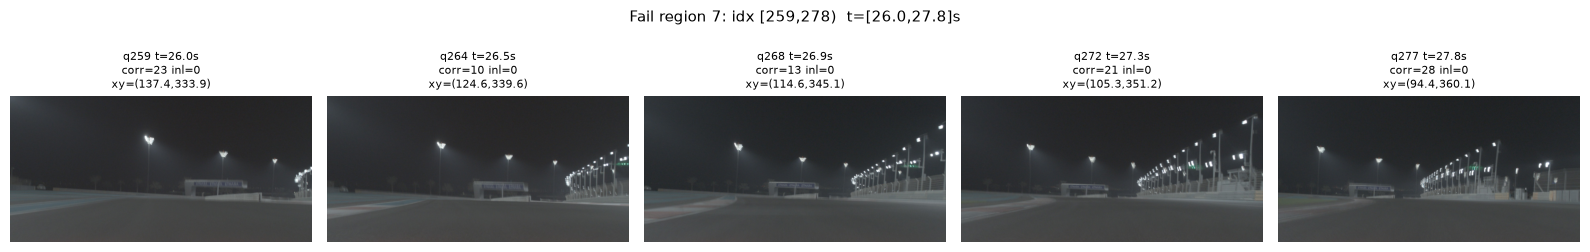


=== region[8] n_fail=10 sample=[285, 287, 290, 292, 294] ===
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/region_08_idx285-294


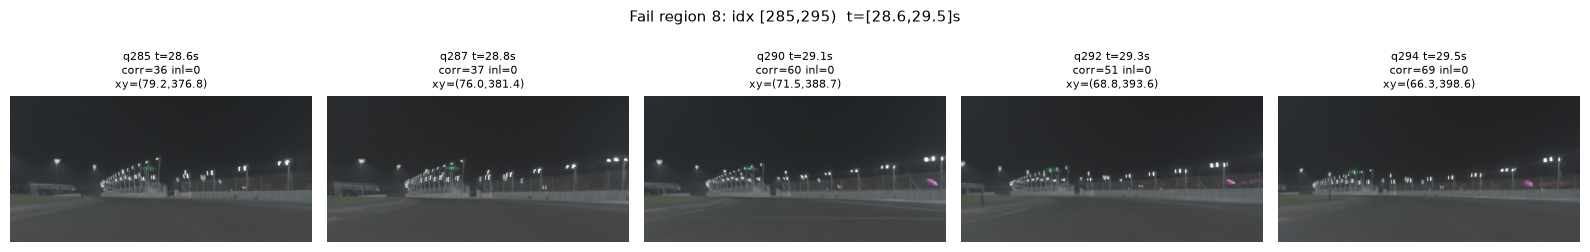


=== region[9] n_fail=6 sample=[303, 304, 306, 307, 308] ===
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/region_09_idx303-308


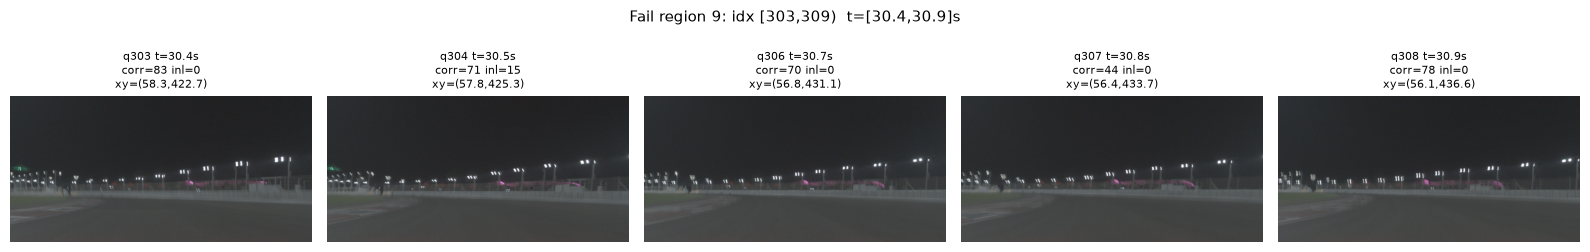


=== region[10] n_fail=4 sample=[55, 56, 57, 58] ===
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/region_10_idx55-58


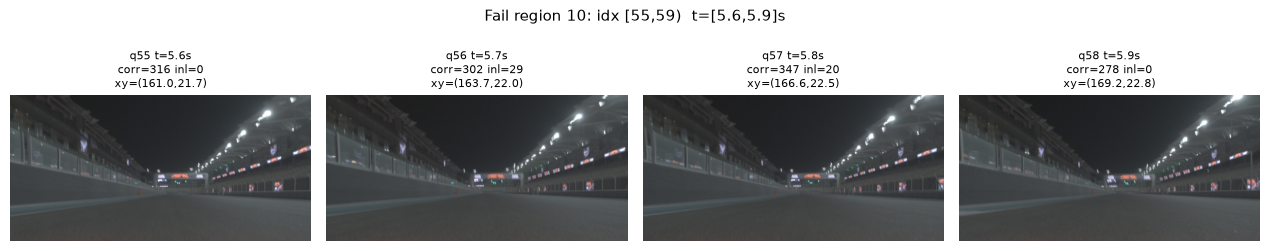


=== region[11] n_fail=4 sample=[1218, 1219, 1220, 1221] ===
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/region_11_idx1218-1221


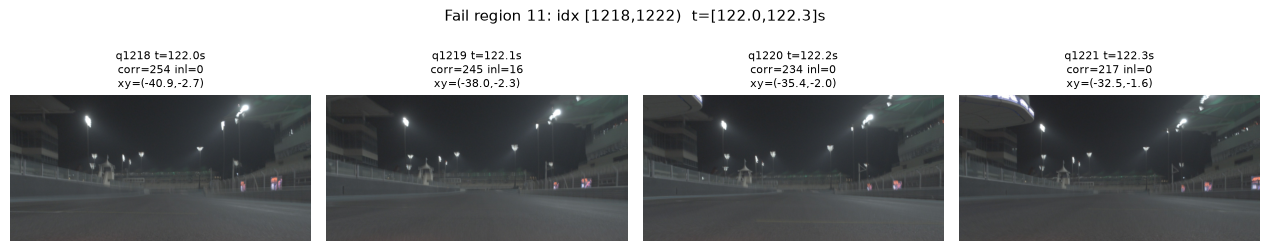

wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3/fail_regions/fail_region_samples.csv


In [24]:
FAIL_MIN_LEN = 3          # 最短连续失败长度（合并后）
FAIL_GAP_MERGE = 2        # 中间成功帧 ≤ 此值仍并入同一失败区
FAIL_N_PER_REGION = 5     # 每区抽取张数

fail = ~ok_mask
n_fail = int(fail.sum())
print(f"hard fails (ok=False): {n_fail}/{len(results)}")

# --- 连续失败段 + 近邻合并 ---
raw_segs = []
i = 0
N = len(fail)
while i < N:
    if not fail[i]:
        i += 1
        continue
    j = i
    while j < N and fail[j]:
        j += 1
    raw_segs.append([i, j])  # [start, end)
    i = j

merged = []
for s, e in raw_segs:
    if not merged:
        merged.append([s, e])
        continue
    ps, pe = merged[-1]
    gap = s - pe
    if 0 < gap <= FAIL_GAP_MERGE:
        merged[-1][1] = e
    else:
        merged.append([s, e])

regions = [(s, e) for s, e in merged if (e - s) >= FAIL_MIN_LEN]
regions.sort(key=lambda se: -(se[1] - se[0]))
print(f"concentrated fail regions (len>={FAIL_MIN_LEN}): {len(regions)}")
for k, (s, e) in enumerate(regions):
    print(
        f"  region[{k}] idx=[{s},{e}) n={e-s}  "
        f"t=[{t_rel[s]:.1f},{t_rel[e-1]:.1f}]s  "
        f"xy≈({gt_xy[s,0]:.1f},{gt_xy[s,1]:.1f})→({gt_xy[e-1,0]:.1f},{gt_xy[e-1,1]:.1f})"
    )

fail_dir = loc_dir / "fail_regions"
fail_dir.mkdir(parents=True, exist_ok=True)

# 轨迹上标失败区中心
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(track_left[:, 0], track_left[:, 1], color="#7f8c8d", lw=0.7)
ax.plot(track_right[:, 0], track_right[:, 1], color="#95a5a6", lw=0.7)
ax.plot(gt_xy[:, 0], gt_xy[:, 1], color="#27ae60", lw=1.2, alpha=0.7, label="GT")
if fail.any():
    ax.scatter(gt_xy[fail, 0], gt_xy[fail, 1], c="#e74c3c", s=8, alpha=0.5, label="ok=False")
for k, (s, e) in enumerate(regions):
    mid = (s + e - 1) // 2
    ax.scatter([gt_xy[mid, 0]], [gt_xy[mid, 1]], c="#8e44ad", s=80, zorder=5)
    ax.annotate(f"R{k}", (gt_xy[mid, 0], gt_xy[mid, 1]), fontsize=9, color="#8e44ad")
ax.set_aspect("equal", adjustable="box")
ax.set_title(f"Lap {QUERY_LAP}: concentrated fail regions")
ax.legend(loc="best", frameon=False)
ax.grid(True, alpha=0.25)
fig.tight_layout()
reg_map_path = fail_dir / "fail_regions_on_track.png"
fig.savefig(reg_map_path, dpi=140)
print("saved", reg_map_path)
plt.show()

# --- 每区均匀抽 5 张 ---
def sample_indices(s: int, e: int, n: int) -> list[int]:
    if e <= s:
        return []
    length = e - s
    if length <= n:
        return list(range(s, e))
    # 均匀含首尾
    pos = np.linspace(s, e - 1, n)
    return [int(round(p)) for p in pos]

region_samples = []
for k, (s, e) in enumerate(regions):
    idxs = sample_indices(s, e, FAIL_N_PER_REGION)
    region_samples.append({"region": k, "span": (s, e), "idxs": idxs})
    rdir = fail_dir / f"region_{k:02d}_idx{s}-{e-1}"
    rdir.mkdir(parents=True, exist_ok=True)

    fig, axes = plt.subplots(1, len(idxs), figsize=(3.2 * len(idxs), 3.0))
    if len(idxs) == 1:
        axes = [axes]
    print(f"\n=== region[{k}] n_fail={e-s} sample={idxs} ===")
    for ax, qi in zip(axes, idxs):
        q = query_frames[qi]
        r = results[qi]
        rgb = cv2.cvtColor(q.bgr_undist, cv2.COLOR_BGR2RGB)
        ax.imshow(rgb)
        ax.set_title(
            f"q{qi} t={t_rel[qi]:.1f}s\n"
            f"corr={r['n_pnp_corr']} inl={r['n_pnp_inl']}\n"
            f"xy=({q.gt_xyzyaw[0]:.1f},{q.gt_xyzyaw[1]:.1f})",
            fontsize=8,
        )
        ax.axis("off")
        out_img = rdir / f"q{qi:04d}_t{t_rel[qi]:.1f}s.jpg"
        cv2.imwrite(str(out_img), q.bgr_undist)
    fig.suptitle(
        f"Fail region {k}: idx [{s},{e})  t=[{t_rel[s]:.1f},{t_rel[e-1]:.1f}]s",
        fontsize=11,
    )
    fig.tight_layout()
    montage = rdir / "montage.png"
    fig.savefig(montage, dpi=130)
    print("saved", rdir)
    plt.show()

if not regions:
    print("no concentrated fail regions (try lowering FAIL_MIN_LEN)")
else:
    # 清单 CSV
    rows_f = []
    for rs in region_samples:
        for qi in rs["idxs"]:
            q = query_frames[qi]
            r = results[qi]
            rows_f.append(
                {
                    "region": rs["region"],
                    "span_start": rs["span"][0],
                    "span_end": rs["span"][1] - 1,
                    "query_idx": qi,
                    "t_rel_s": float(t_rel[qi]),
                    "gt_x": float(q.gt_xyzyaw[0]),
                    "gt_y": float(q.gt_xyzyaw[1]),
                    "n_pnp_corr": r["n_pnp_corr"],
                    "n_pnp_inl": r["n_pnp_inl"],
                    "topk": json.dumps(r["topk"]),
                }
            )
    pd.DataFrame(rows_f).to_csv(fail_dir / "fail_region_samples.csv", index=False)
    print("wrote", fail_dir / "fail_region_samples.csv")

## 9. `camera_fl`：Lap2 独立建图 + Lap3 定位（不融合）

与 §2–7 同构，输出到 `outputs/map_fl/`、`outputs/loc_lap3_fl/`。若已有 `map_fl/map_bundle.npz` 且 `OVERRIDE_MAP=False`，跳过建图只跑 query。


load camera_fl:   0%|          | 0/1675 [00:00<?, ?frm/s]

[fl] map frames=1676  (21.2s)


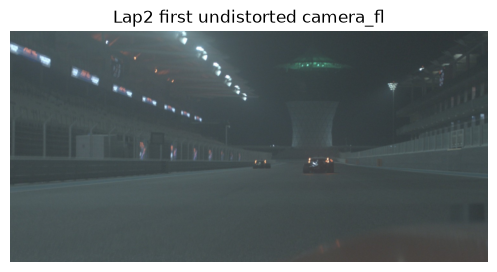

SuperPoint(+NetVLAD):   0%|          | 0/1676 [00:00<?, ?frm/s]

[fl] feature extract 375.8s
[fl] kpts med/min/max 173.0 35 304


SfM triangulate:   0%|          | 0/1676 [00:00<?, ?frm/s]

[fl] points=39303  obs=39303  (229.9s)
[fl] wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/map_fl/map_bundle.npz


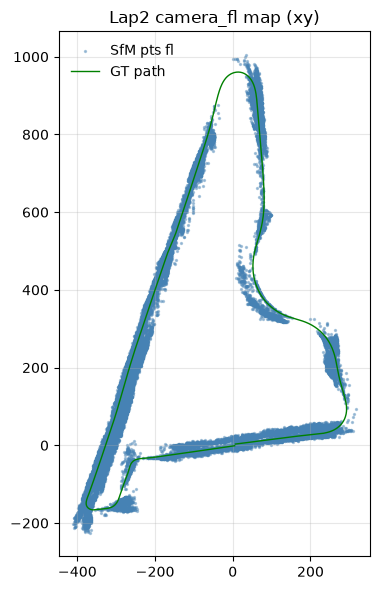

load camera_fl:   0%|          | 0/1236 [00:00<?, ?frm/s]

[fl] query frames=1236  load 15.3s


SuperPoint(+NetVLAD):   0%|          | 0/1236 [00:00<?, ?frm/s]

[fl] query features 254.8s


localize Lap3 fl:   0%|          | 0/1236 [00:00<?, ?qry/s]

[fl 0] ok=True n_corr=129 inl=43 err_xy=0.45534026520441434
[fl 1] ok=True n_corr=115 inl=22 err_xy=0.9571857391526791
[fl 2] ok=True n_corr=105 inl=16 err_xy=0.8789167178224853
[fl 3] ok=True n_corr=80 inl=14 err_xy=2.15277548690802
[fl 4] ok=True n_corr=91 inl=13 err_xy=1.1059380336565432
[fl 5] ok=True n_corr=84 inl=12 err_xy=21.869933138201674
[fl 6] ok=False n_corr=112 inl=0 err_xy=None
[fl 7] ok=True n_corr=87 inl=12 err_xy=18.58403570192121
[fl 8] ok=True n_corr=99 inl=12 err_xy=2.841280515247341
[fl 9] ok=False n_corr=82 inl=0 err_xy=None
[fl 10] ok=False n_corr=77 inl=0 err_xy=None
[fl 11] ok=False n_corr=102 inl=0 err_xy=None
[fl 12] ok=True n_corr=108 inl=14 err_xy=0.92959930143795
[fl 13] ok=False n_corr=116 inl=0 err_xy=None
[fl 14] ok=True n_corr=110 inl=13 err_xy=5.420713891317139
[fl 15] ok=True n_corr=139 inl=14 err_xy=0.890113679108795
[fl 16] ok=True n_corr=127 inl=14 err_xy=3.7106496169460232
[fl 17] ok=True n_corr=108 inl=21 err_xy=0.9497630451182425
[fl 18] ok=Tru

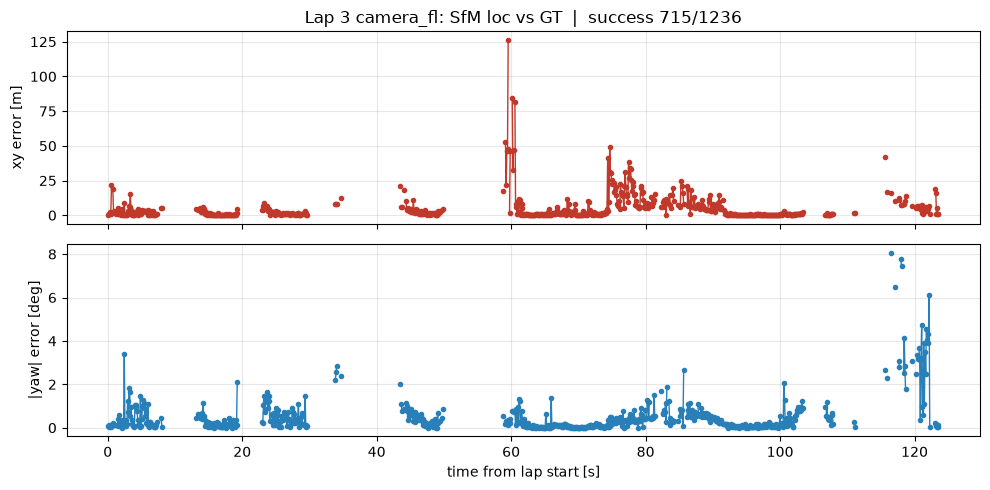

saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3_fl/lap03_traj_vs_gt.png


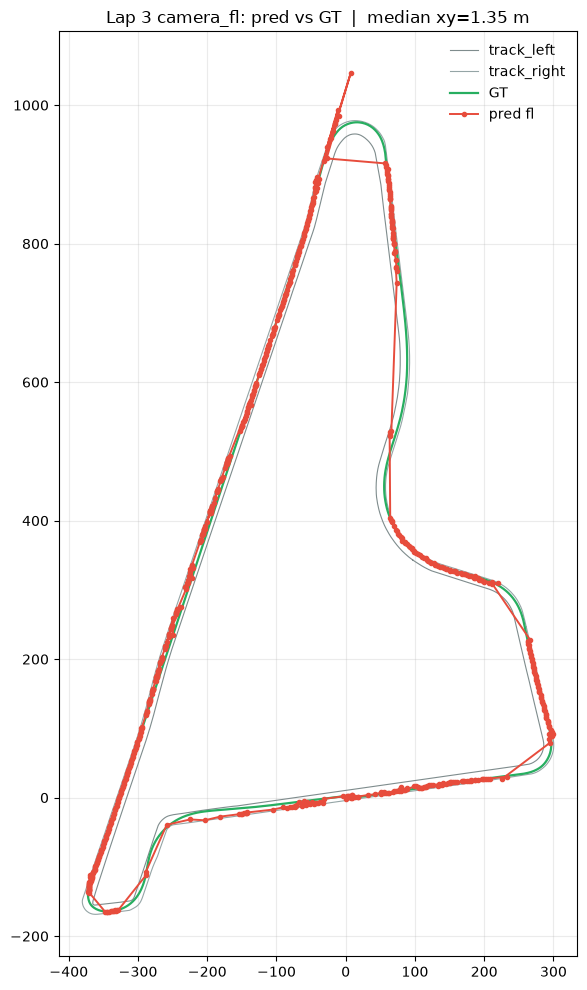

In [25]:
RUN_FL = globals().get("RUN_FL", True)
OVERRIDE_MAP = globals().get("OVERRIDE_MAP", False)
if not RUN_FL:
    print("SKIP camera_fl (RUN_FL=False)")
else:
    if "local" not in dir() or local is None:
        local = sfm.LocalFeatures(max_keypoints=SP_MAX_KP, resize=SP_RESIZE)
        print("local device", local.device, "resize", local.resize)
    if USE_NETVLAD and ("netvlad" not in dir() or netvlad is None):
        print("loading NetVLAD...")
        netvlad = sfm.NetVLADGlobal(device=local.device)
    if "calib_fl" not in dir():
        calib_fl = sfm.load_camera_calib("fl")

    map_dir_fl = OUT / "map_fl"
    loc_dir_fl = OUT / "loc_lap3_fl"
    map_dir_fl.mkdir(parents=True, exist_ok=True)
    loc_dir_fl.mkdir(parents=True, exist_ok=True)
    SKIP_MAP_FL = sfm.map_ready(map_dir_fl) and not OVERRIDE_MAP

    if SKIP_MAP_FL:
        print(f"SKIP rebuild camera_fl map — load {map_dir_fl / sfm.MAP_BUNDLE_NAME}")
        map_frames_fl, points_fl = sfm.load_map_bundle(map_dir_fl)
        observations_fl = []
        print(f"[fl] loaded map_frames={len(map_frames_fl)} points={len(points_fl)}")
    else:
        if sfm.map_ready(map_dir_fl) and OVERRIDE_MAP:
            print("OVERRIDE_MAP=True — rebuilding camera_fl map")
        t0 = time.perf_counter()
        map_frames_fl = sfm.extract_frames_from_mcap(
            sfm.DEFAULT_MCAP,
            int(lap_map["start_ns"]),
            int(lap_map["end_ns"]),
            calib_fl,
            gt,
            camera="fl",
            max_frames=MAP_MAX_FRAMES,
            stride=MAP_STRIDE,
        )
        print(f"[fl] map frames={len(map_frames_fl)}  ({time.perf_counter()-t0:.1f}s)")
        if map_frames_fl and map_frames_fl[0].bgr_undist.size > 3:
            plt.figure(figsize=(10, 3))
            plt.imshow(cv2.cvtColor(map_frames_fl[0].bgr_undist, cv2.COLOR_BGR2RGB))
            plt.title("Lap2 first undistorted camera_fl")
            plt.axis("off")
            plt.show()

        t0 = time.perf_counter()
        sfm.run_local_and_global(
            map_frames_fl, local, netvlad if USE_NETVLAD else None, min_nn_dist=MIN_NN_DIST
        )
        print(f"[fl] feature extract {time.perf_counter()-t0:.1f}s")
        nk = [len(f.kpts) for f in map_frames_fl]
        print("[fl] kpts med/min/max", float(np.median(nk)), int(np.min(nk)), int(np.max(nk)))

        t0 = time.perf_counter()
        points_fl, observations_fl = sfm.build_map(
            map_frames_fl,
            local,
            calib_fl.K,
            window=MATCH_WINDOW,
            min_baseline_m=0.8,
            epi_thresh_px=EPI_THRESH_PX,
        )
        print(f"[fl] points={len(points_fl)}  obs={len(observations_fl)}  ({time.perf_counter()-t0:.1f}s)")
        bundle_fl = sfm.save_map_bundle(map_dir_fl, map_frames_fl, points_fl)
        print("[fl] wrote", bundle_fl)

    if len(points_fl):
        xy = np.array([f.gt_xyzyaw[:2] for f in map_frames_fl])
        fig, ax = plt.subplots(figsize=(6, 6))
        ax.scatter(points_fl[:, 0], points_fl[:, 1], s=2, c="steelblue", alpha=0.4, label="SfM pts fl")
        ax.plot(xy[:, 0], xy[:, 1], "g-", lw=1, label="GT path")
        ax.set_aspect("equal", adjustable="box")
        ax.legend(loc="best", frameon=False)
        ax.set_title("Lap2 camera_fl map (xy)" + (" [loaded]" if SKIP_MAP_FL else ""))
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        fig.savefig(map_dir_fl / "map_xy.png", dpi=120)
        plt.show()

    # --- Lap3 query (always runs) ---
    if not USE_NETVLAD:
        raise RuntimeError("定位段需要 USE_NETVLAD=True")
    if len(points_fl) < 30:
        print("WARNING: [fl] few map points; localization may fail")

    t0 = time.perf_counter()
    query_frames_fl = sfm.extract_frames_from_mcap(
        sfm.DEFAULT_MCAP,
        int(lap_q["start_ns"]),
        int(lap_q["end_ns"]),
        calib_fl,
        gt,
        camera="fl",
        max_frames=QUERY_MAX_FRAMES,
        stride=QUERY_STRIDE,
    )
    print(f"[fl] query frames={len(query_frames_fl)}  load {time.perf_counter()-t0:.1f}s")

    t0 = time.perf_counter()
    sfm.run_local_and_global(query_frames_fl, local, netvlad, min_nn_dist=MIN_NN_DIST)
    print(f"[fl] query features {time.perf_counter()-t0:.1f}s")

    from tqdm.auto import tqdm

    results_fl = []
    t0 = time.perf_counter()
    for i, q in enumerate(tqdm(query_frames_fl, desc="localize Lap3 fl", unit="qry")):
        r = sfm.localize_query(
            q,
            map_frames_fl,
            points_fl,
            local,
            calib_fl.K,
            calib_fl.T_base_cam,
            top_k=TOP_K,
        )
        results_fl.append(r)
        if i < 20 or (i + 1) % 50 == 0 or not r["ok"]:
            tqdm.write(
                f"[fl {i}] ok={r['ok']} n_corr={r['n_pnp_corr']} inl={r['n_pnp_inl']} "
                f"err_xy={r['err_xy']}"
            )
    print(f"[fl] localize {time.perf_counter()-t0:.1f}s")

    import pandas as pd

    stamps_fl = np.array([q.stamp_ns for q in query_frames_fl], dtype=np.int64)
    t0_ns = int(lap_q["start_ns"])
    t_rel_fl = (stamps_fl - t0_ns) * 1e-9
    gt_xy_fl = np.array([q.gt_xyzyaw[:2] for q in query_frames_fl], dtype=np.float64)
    pred_xy_fl = np.full((len(results_fl), 2), np.nan)
    err_xy_fl = np.full(len(results_fl), np.nan)
    err_yaw_fl = np.full(len(results_fl), np.nan)
    ok_fl = np.array([bool(r["ok"]) for r in results_fl])

    rows = []
    for i, (q, r) in enumerate(zip(query_frames_fl, results_fl)):
        if r["ok"]:
            pred_xy_fl[i] = r["pred"][:2]
            err_xy_fl[i] = r["err_xy"]
            err_yaw_fl[i] = abs(r["err_yaw_deg"])
        rows.append(
            {
                "idx": i,
                "stamp_ns": int(q.stamp_ns),
                "t_rel_s": float(t_rel_fl[i]),
                "ok": bool(r["ok"]),
                "gt_x": float(q.gt_xyzyaw[0]),
                "gt_y": float(q.gt_xyzyaw[1]),
                "gt_yaw": float(q.gt_xyzyaw[3]),
                "pred_x": None if not r["ok"] else float(r["pred"][0]),
                "pred_y": None if not r["ok"] else float(r["pred"][1]),
                "pred_yaw": None if not r["ok"] else float(r["pred"][3]),
                "err_xy": r["err_xy"],
                "err_yaw_deg": None if r["err_yaw_deg"] is None else abs(r["err_yaw_deg"]),
                "n_pnp_corr": r["n_pnp_corr"],
                "n_pnp_inl": r["n_pnp_inl"],
                "topk": json.dumps(r["topk"]),
            }
        )
    df_fl = pd.DataFrame(rows)
    df_fl.to_csv(loc_dir_fl / "errors.csv", index=False)
    print("wrote", loc_dir_fl / "errors.csv")
    print(f"[fl] success {ok_fl.sum()}/{len(results_fl)}")
    if ok_fl.any():
        summary_fl = {
            "xy_mean_m": float(np.nanmean(err_xy_fl)),
            "xy_median_m": float(np.nanmedian(err_xy_fl)),
            "xy_p95_m": float(np.nanpercentile(err_xy_fl, 95)),
            "yaw_median_deg": float(np.nanmedian(err_yaw_fl)),
        }
        print("[fl]", summary_fl)
    else:
        summary_fl = {"xy_median_m": float("nan"), "xy_p95_m": float("nan")}

    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    axes[0].plot(t_rel_fl, err_xy_fl, color="#c0392b", lw=1.0, marker="o", ms=3)
    axes[0].set_ylabel("xy error [m]")
    axes[0].grid(True, alpha=0.3)
    axes[0].set_title(
        f"Lap {QUERY_LAP} camera_fl: SfM loc vs GT  |  success {ok_fl.sum()}/{len(results_fl)}"
    )
    axes[1].plot(t_rel_fl, err_yaw_fl, color="#2980b9", lw=1.0, marker="o", ms=3)
    axes[1].set_ylabel("|yaw| error [deg]")
    axes[1].set_xlabel("time from lap start [s]")
    axes[1].grid(True, alpha=0.3)
    fig.tight_layout()
    err_path = loc_dir_fl / f"lap{QUERY_LAP:02d}_err_vs_time.png"
    fig.savefig(err_path, dpi=150)
    print("saved", err_path)
    plt.show()

    with open(sfm.EXTRACTED / "track_bounds.json") as f:
        track_bounds = json.load(f)

    def _poly(key):
        return np.array([[p["x"], p["y"]] for p in track_bounds[key]["points"]], dtype=np.float64)

    track_left = _poly("track_left")
    track_right = _poly("track_right")
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.plot(track_left[:, 0], track_left[:, 1], color="#7f8c8d", lw=0.8, label="track_left")
    ax.plot(track_right[:, 0], track_right[:, 1], color="#95a5a6", lw=0.8, label="track_right")
    ax.plot(gt_xy_fl[:, 0], gt_xy_fl[:, 1], color="#27ae60", lw=1.6, label="GT")
    if ok_fl.any():
        ax.plot(
            pred_xy_fl[ok_fl, 0],
            pred_xy_fl[ok_fl, 1],
            color="#e74c3c",
            lw=1.4,
            marker="o",
            ms=3,
            label="pred fl",
        )
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(
        f"Lap {QUERY_LAP} camera_fl: pred vs GT  |  median xy={summary_fl['xy_median_m']:.2f} m"
    )
    ax.legend(loc="best", frameon=False)
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    traj_path = loc_dir_fl / f"lap{QUERY_LAP:02d}_traj_vs_gt.png"
    fig.savefig(traj_path, dpi=150)
    print("saved", traj_path)
    plt.show()


## 10. `r` vs `fl` 对齐对比（不融合）

用最近邻时间戳配对，统计单路成功率、**至少一路成功** \(P(A\cup B)\)、以及 \(P(B\mid \neg A)\)（`r` 失败时 `fl` 能否救）。需已跑完 §6–7 与 §9。


paired 1235 frames  |Δt| med=8.18 µs  max=4194.54 µs
P(ok_r)           = 57.4%  (709/1235)
P(ok_fl)          = 57.8%  (714/1235)
P(ok_r ∪ ok_fl)   = 70.4%  (870/1235)   Δ vs r: +13.0 pp
P(ok_fl | fail_r) = 30.6%  (save 161/526 r-fails)
P(ok_r  | fail_fl)= 29.9%
both fail         = 365 (29.6%)
only r / only fl / both ok = 156 / 161 / 553
wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3_compare/pair_errors.csv
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3_compare/complementarity_on_track.png


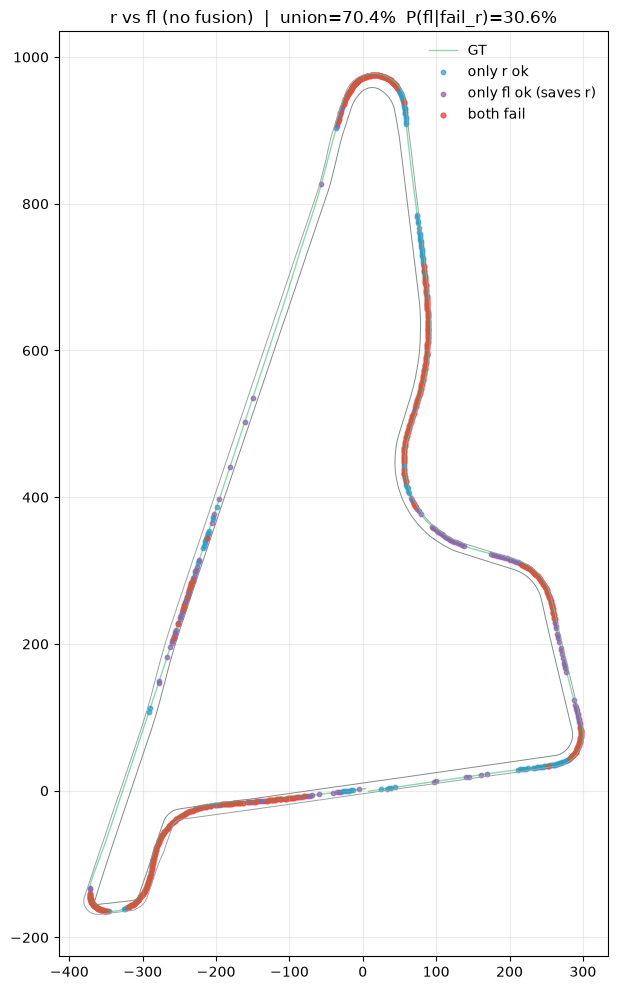

saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs/loc_lap3_compare/ok_strips.png


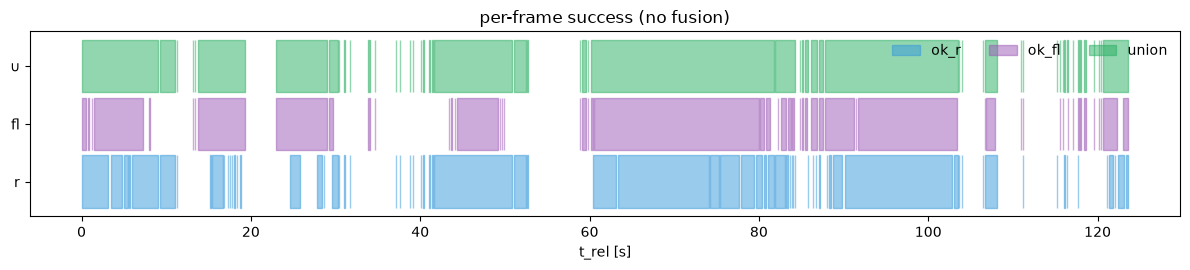

In [26]:
import pandas as pd

cmp_dir = OUT / "loc_lap3_compare"
cmp_dir.mkdir(parents=True, exist_ok=True)

path_r = OUT / "loc_lap3" / "errors.csv"
path_fl = OUT / "loc_lap3_fl" / "errors.csv"
if not path_r.is_file():
    raise FileNotFoundError(f"need {path_r} (run camera_r loc first)")
RUN_FL = globals().get("RUN_FL", True)
if not RUN_FL or not path_fl.is_file():
    raise FileNotFoundError(f"need {path_fl} (run §9 with RUN_FL=True)")

df_r = pd.read_csv(path_r)
df_fl = pd.read_csv(path_fl)
tr = df_r["stamp_ns"].to_numpy(np.int64)
tf = df_fl["stamp_ns"].to_numpy(np.int64)
# for each r, nearest fl
idx = np.searchsorted(tf, tr)
pairs = []
for i, t in enumerate(tr):
    cands = []
    if idx[i] < len(tf):
        cands.append(idx[i])
    if idx[i] > 0:
        cands.append(idx[i] - 1)
    j = min(cands, key=lambda k: abs(int(tf[k]) - int(t)))
    dt_us = (int(tf[j]) - int(t)) * 1e-3
    pairs.append((i, j, dt_us))

ok_r = df_r["ok"].astype(bool).to_numpy()
ok_f = np.array([bool(df_fl.iloc[j]["ok"]) for _, j, _ in pairs])
dt = np.array([p[2] for p in pairs])
print(f"paired {len(pairs)} frames  |Δt| med={np.median(np.abs(dt)):.2f} µs  max={np.max(np.abs(dt)):.2f} µs")

A, B = ok_r, ok_f
n = len(A)
pA = A.mean()
pB = B.mean()
pU = (A | B).mean()
pB_notA = B[~A].mean() if (~A).any() else float("nan")
pA_notB = A[~B].mean() if (~B).any() else float("nan")
print(f"P(ok_r)           = {pA*100:.1f}%  ({A.sum()}/{n})")
print(f"P(ok_fl)          = {pB*100:.1f}%  ({B.sum()}/{n})")
print(f"P(ok_r ∪ ok_fl)   = {pU*100:.1f}%  ({(A|B).sum()}/{n})   Δ vs r: {(pU-pA)*100:+.1f} pp")
print(f"P(ok_fl | fail_r) = {pB_notA*100:.1f}%  (save {int(B[~A].sum())}/{int((~A).sum())} r-fails)")
print(f"P(ok_r  | fail_fl)= {pA_notB*100:.1f}%")
print(f"both fail         = {((~A)&(~B)).sum()} ({((~A)&(~B)).mean()*100:.1f}%)")
print(f"only r / only fl / both ok = {((A)&(~B)).sum()} / {((~A)&(B)).sum()} / {(A&B).sum()}")

rows = []
for i, j, dt_us in pairs:
    rr, ff = df_r.iloc[i], df_fl.iloc[j]
    rows.append(
        {
            "stamp_r": int(rr.stamp_ns),
            "stamp_fl": int(ff.stamp_ns),
            "dt_us": float(dt_us),
            "ok_r": bool(rr.ok),
            "ok_fl": bool(ff.ok),
            "err_xy_r": rr.err_xy,
            "err_xy_fl": ff.err_xy,
            "gt_x": float(rr.gt_x),
            "gt_y": float(rr.gt_y),
            "t_rel_s": float(rr.t_rel_s),
        }
    )
df_pair = pd.DataFrame(rows)
df_pair.to_csv(cmp_dir / "pair_errors.csv", index=False)
print("wrote", cmp_dir / "pair_errors.csv")

# trajectory: fail masks
with open(sfm.EXTRACTED / "track_bounds.json") as f:
    track_bounds = json.load(f)
tl = np.array([[p["x"], p["y"]] for p in track_bounds["track_left"]["points"]], float)
trb = np.array([[p["x"], p["y"]] for p in track_bounds["track_right"]["points"]], float)
xy = df_pair[["gt_x", "gt_y"]].to_numpy()
fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(tl[:, 0], tl[:, 1], color="#7f8c8d", lw=0.7)
ax.plot(trb[:, 0], trb[:, 1], color="#95a5a6", lw=0.7)
ax.plot(xy[:, 0], xy[:, 1], color="#27ae60", lw=1.0, alpha=0.5, label="GT")
m_only_r = A & ~B
m_only_f = ~A & B
m_both_f = ~A & ~B
ax.scatter(xy[m_only_r, 0], xy[m_only_r, 1], c="#3498db", s=10, label="only r ok", alpha=0.7)
ax.scatter(xy[m_only_f, 0], xy[m_only_f, 1], c="#9b59b6", s=10, label="only fl ok (saves r)", alpha=0.7)
ax.scatter(xy[m_both_f, 0], xy[m_both_f, 1], c="#e74c3c", s=12, label="both fail", alpha=0.8)
ax.set_aspect("equal", adjustable="box")
ax.set_title(
    f"r vs fl (no fusion)  |  union={pU*100:.1f}%  P(fl|fail_r)={pB_notA*100:.1f}%"
)
ax.legend(loc="best", frameon=False)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(cmp_dir / "complementarity_on_track.png", dpi=140)
print("saved", cmp_dir / "complementarity_on_track.png")
plt.show()

# time strips
fig, ax = plt.subplots(figsize=(12, 2.8))
t = df_pair["t_rel_s"].to_numpy()
ax.fill_between(t, 0, 1, where=A, color="#3498db", alpha=0.5, step="mid", label="ok_r")
ax.fill_between(t, 1.1, 2.1, where=B, color="#9b59b6", alpha=0.5, step="mid", label="ok_fl")
ax.fill_between(t, 2.2, 3.2, where=(A | B), color="#27ae60", alpha=0.5, step="mid", label="union")
ax.set_yticks([0.5, 1.6, 2.7])
ax.set_yticklabels(["r", "fl", "∪"])
ax.set_xlabel("t_rel [s]")
ax.set_title("per-frame success (no fusion)")
ax.legend(loc="upper right", ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(cmp_dir / "ok_strips.png", dpi=140)
print("saved", cmp_dir / "ok_strips.png")
plt.show()


## 调参提示

| 参数 | 作用 |
|---|---|
| `MAP_MAX_FRAMES` / `MAP_STRIDE` | 建图覆盖与耗时 |
| `MIN_NN_DIST` | 越大过滤越狠（更少重复灯点） |
| `EPI_THRESH_PX` | 极线内点松紧 |
| `SP_RESIZE` | 512 快 / 1024 更密 |
| `TOP_K` | 检索候选数（文档默认 5） |

烟测示例：`MAP_MAX_FRAMES=40`、`QUERY_MAX_FRAMES=12`、`MAP_STRIDE=2`、`QUERY_STRIDE=5`。

| `RUN_FL` | 是否跑 §9–10 `camera_fl` |
| `camera` | `extract_frames_from_mcap(..., camera="fl")` |
| `OVERRIDE_MAP` | `True` 强制重建图；默认跳过已有 `map_bundle.npz` |
